In [4]:
from pathlib import Path
BASE = Path("/home/lka/HYBRID_SARIMA")
print(BASE.exists(), BASE)

#Import the file to read it
import pandas as pd
disocupati_trimestral = pd.read_csv(BASE / 'data.csv', 
                       index_col='Period', 
                       parse_dates=True)
print(disocupati_trimestral)

True /home/lka/HYBRID_SARIMA
             15-34 M    15-34 F   35-49 M   35-49 F   50-74 M   50-74 F  \
Period                                                                    
2004-Q1    11.720628  17.198032  4.283283  8.776062  4.004764  5.376203   
2004-Q2    11.410664  16.187372  3.654493  7.196378  3.636536  4.515018   
2004-Q3    10.041510  15.682014  3.520125  6.945425  3.394804  3.976243   
2004-Q4    11.918557  17.227696  4.020448  7.582207  3.604743  3.583677   
2005-Q1    12.334781  16.852636  4.316241  7.577546  3.440298  4.204936   
...              ...        ...       ...       ...       ...       ...   
2025-Q2    11.341464  13.635416  5.106017  7.025122  3.776334  3.889283   
2025-Q3     9.628072  11.355385  4.656108  6.239399  3.108541  3.482718   
2025-Q4    10.903735  10.928362  3.989899  5.704370  3.250742  3.129547   
2026-Q1     9.534584  10.900056  4.316380  5.611548  2.984988  3.392216   
2026-Q2    10.244865  11.855438  5.044973  6.388627  3.268385  3.460483

In [5]:
#Dividir el dataset en training, validation y test
series = [
    '15-34 M', '15-34 F',
    '35-49 M', '35-49 F',
    '50-74 M', '50-74 F',
    'Global_Rate'
]

# Ordenar cronológicamente
df = disocupati_trimestral

# División 70% Train, 15% Validation, 15% Test
n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train = df[series].iloc[:train_end].copy()
val = df[series].iloc[train_end:val_end].copy()
test = df[series].iloc[val_end:].copy()

# Mostrar resultados para cada serie
#for serie in series:
#    print(f"\nSerie: {serie}")
#    print(f"Train: {len(train[serie])} observaciones")
#    print(f"Validation: {len(val[serie])} observaciones")
#    print(f"Test: {len(test[serie])} observaciones")

print(train)
print(val)
print(test)


             15-34 M    15-34 F   35-49 M    35-49 F   50-74 M   50-74 F  \
Period                                                                     
2004-Q1    11.720628  17.198032  4.283283   8.776062  4.004764  5.376203   
2004-Q2    11.410664  16.187372  3.654493   7.196378  3.636536  4.515018   
2004-Q3    10.041510  15.682014  3.520125   6.945425  3.394804  3.976243   
2004-Q4    11.918557  17.227696  4.020448   7.582207  3.604743  3.583677   
2005-Q1    12.334781  16.852636  4.316241   7.577546  3.440298  4.204936   
...              ...        ...       ...        ...       ...       ...   
2018-Q2    17.908050  21.321705  7.759217  10.435680  6.683032  6.283515   
2018-Q3    16.802144  19.343542  6.191831   9.120602  5.538136  5.299045   
2018-Q4    19.322895  22.132355  7.396393  10.673055  6.327076  6.189145   
2019-Q1    19.163606  21.713279  8.111591  11.250865  6.697788  6.034775   
2019-Q2    17.128382  19.347371  7.161324   9.818228  5.738406  5.356958   

           

In [6]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from itertools import product
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)

pdq=list(product(range(3),repeat=3))
seasonal_pdq=[(P,D,Q,4) for P,D,Q in pdq]
sarima_grid=list(product(pdq,seasonal_pdq))

architectures=[(32,),(64,),(128,),(32,32),(64,32),(64,64),(128,32),(128,64),(128,128)]  # los layers de la LSTM a probar
lstm_grid=list(product(architectures,[0.01,0.001],[4,6,8],[100],[16,32],[0.0,0.1,0.3])) # grid de hiperparámetros de la LSTM a probar

class LSTM(nn.Module):                              # clase LSTM para modelar los residuos
    def __init__(self,neurons,dropout):             # función de inicialización de la LSTM
        super().__init__()                          # aqui se utliza super(). como parametro para inicializar la clase base
        self.layers=nn.ModuleList()                 # se crea una lista de capas LSTM
        size=1                                      # tamaño de entrada inicial
        for n in neurons:
            self.layers.append(nn.LSTM(size,n,batch_first=True))  # se añade una capa LSTM a la lista
            size=n
        self.drop=nn.Dropout(dropout)               # capa de dropout
        self.fc=nn.Linear(size,1)                   # capa fully connected final

    def forward(self, x):                            # función forward de la LSTM
        for i, layer in enumerate(self.layers):
            x, _ = layer(x)
            if i == 0:
                x = self.drop(x)                      # aplicar dropout solo a la primera capa LSTM
        return self.fc(x[:, -1, :])

def sequences(z,w,start,end):                          # función para generar secuencias de entrada y salida para la LSTM
    X=np.array([z[i-w:i] for i in range(start,end)],dtype=np.float32)  # generar secuencias de entrada
    y=np.array(z[start:end],dtype=np.float32)                           # generar secuencias de salida
    return torch.tensor(X.reshape(-1,w,1),device=device),torch.tensor(y.reshape(-1,1),device=device)  # convertir a tensores de PyTorch y devolver

def train_lstm(res_train,res_val,sarima_val,y_val,config,final=False,best_epoch=None):
    # función para entrenar la LSTM sobre los residuos del modelo SARIMA
    neurons,lr,w,epochs,batch,dropout=config
    torch.manual_seed(42)
    scaler=MinMaxScaler()
    a=scaler.fit_transform(res_train.reshape(-1,1)).ravel()

    if final:
        z=a
    else:
        b=scaler.transform(res_val.reshape(-1,1)).ravel()
        z=np.concatenate([a,b])

    X,y=sequences(z,w,w,len(a) if not final else len(z))
    model=LSTM(neurons,dropout).to(device)
    optimizer=torch.optim.Adam(model.parameters(),lr=lr)
    criterion=nn.MSELoss()
    best=np.inf
    best_ep=0
    wait=0

    if not final:
        Xv,_=sequences(z,w,len(a),len(z))

    for epoch in range(best_epoch if final else epochs):
        model.train()
        idx=torch.randperm(len(X),device=device)

        for ids in idx.split(batch):
            optimizer.zero_grad()
            loss=criterion(model(X[ids]),y[ids])
            loss.backward()
            optimizer.step()

        if not final:
            model.eval()
            with torch.no_grad():
                pred=model(Xv).cpu().numpy()

            residual_pred=scaler.inverse_transform(pred).ravel()
            mse=mean_squared_error(y_val,sarima_val+residual_pred)

            if mse<best-1e-10:
                best=mse
                best_ep=epoch+1
                wait=0
            else:
                wait+=1

            if wait>=15:
                break

    if final:
        model.eval()
        return model,scaler

    return best,best_ep,epoch+1

grid_results=[]
results=[]
best_params={}
hybrid_predictions={}

for col in train.columns:
    y_train=train[col].astype(float).reset_index(drop=True)
    y_val=val[col].astype(float).reset_index(drop=True)
    y_test=test[col].astype(float)
    y_train_val=pd.concat([y_train,y_val],ignore_index=True)

    best_mse=np.inf
    best_sarima=None
    best_lstm=None
    best_epoch=0

    for order,seasonal in sarima_grid:
        try:
            sarima=SARIMAX(
                y_train,
                order=order,
                seasonal_order=seasonal,
                enforce_stationarity=True,
                enforce_invertibility=True
            ).fit(disp=False,maxiter=200)

            if not sarima.mle_retvals["converged"]:
                continue

            res_train=sarima.resid.to_numpy()[sarima.loglikelihood_burn:] # aquí se eliminan los primeros residuos quemados por la log-verosimilitud porque no son representativos del ajuste final
            sarima_val=np.asarray(sarima.forecast(steps=len(y_val)))  # predicciones del modelo SARIMA para el conjunto de validación
            res_val=y_val.to_numpy()-sarima_val                        # residuos del conjunto de validación

            if len(res_train)<10 or not np.all(np.isfinite(res_train)) or not np.all(np.isfinite(res_val)):  # verificar que los residuos sean válidos
                continue

        except (ValueError,np.linalg.LinAlgError):
            continue

        for config in lstm_grid:
            mse,epoch,trained=train_lstm(res_train,res_val,sarima_val,y_val.to_numpy(),config)
            neurons,lr,w,epochs,batch,dropout=config

            grid_results.append([
                col,order,seasonal,len(neurons),str(neurons),
                lr,w,epochs,epoch,trained,batch,dropout,mse
            ])

            if mse<best_mse:
                best_mse=mse
                best_sarima=(order,seasonal)
                best_lstm=config
                best_epoch=epoch

    if best_sarima is None:
        raise ValueError(f"No valid model for {col}")

    best_params[col]={
        "SARIMA":best_sarima,
        "LSTM":best_lstm,
        "Best_Epoch":best_epoch,
        "MSE_Validation":best_mse
    }

    sarima=SARIMAX(
        y_train_val,
        order=best_sarima[0],
        seasonal_order=best_sarima[1],
        enforce_stationarity=True,
        enforce_invertibility=True
    ).fit(disp=False,maxiter=200)

    residuals=sarima.resid.to_numpy()[sarima.loglikelihood_burn:]
    lstm,scaler=train_lstm(residuals,None,None,None,best_lstm,final=True,best_epoch=best_epoch)

    sarima_pred=np.asarray(sarima.forecast(steps=len(y_test)))
    history=list(residuals)
    lstm_pred=[]

    for i in range(len(y_test)):
        w=best_lstm[2]
        x=scaler.transform(np.array(history[-w:]).reshape(-1,1))
        x=torch.tensor(x.reshape(1,w,1),dtype=torch.float32,device=device)

        with torch.no_grad():
            pred=lstm(x).cpu().numpy()

        pred=scaler.inverse_transform(pred)[0,0]
        lstm_pred.append(pred)
        history.append(float(y_test.iloc[i])-sarima_pred[i])

    lstm_pred=np.array(lstm_pred)
    hybrid_pred=sarima_pred+lstm_pred
    real=y_test.to_numpy()

    mae=mean_absolute_error(real,hybrid_pred)
    mse=mean_squared_error(real,hybrid_pred)
    rmse=np.sqrt(mse)
    mape=np.mean(np.abs((real-hybrid_pred)/real))*100 if np.all(real!=0) else np.nan
    values=y_train_val.to_numpy()
    scale=np.mean(np.abs(values[4:]-values[:-4]))
    mase=mae/scale if scale>0 else np.nan
    r2=r2_score(real,hybrid_pred)

    results.append([col,mae,mse,rmse,mape,mase,r2])

    hybrid_predictions[col]=pd.DataFrame({
        "Observed":real,
        "SARIMA":sarima_pred,
        "LSTM_Residual":lstm_pred,
        "Hybrid":hybrid_pred
    },index=y_test.index)

    print(col,"Validation MSE:",round(best_mse,4),"Test MSE:",round(mse,4))

grid_df=pd.DataFrame(grid_results,columns=[
    "Serie","Order","Seasonal_Order","Layers","Neurons",
    "Learning_Rate","Window","Epochs","Best_Epoch",
    "Epochs_Trained","Batch_Size","Dropout","MSE"
])

grid_df=grid_df.sort_values(["Serie","MSE"]).reset_index(drop=True)
grid_df["Rank"]=grid_df.groupby("Serie").cumcount()+1
top10=grid_df[grid_df["Rank"]<=10]

results_df=pd.DataFrame(results,columns=[
    "Serie","MAE","MSE","RMSE","MAPE","MASE","R2"
])

output=Path("results/SARIMA_LSTM_Joint")
output.mkdir(parents=True,exist_ok=True)
for col, pred in hybrid_predictions.items():
    pred.to_csv(output/f"pred_{col.replace(' ', '_')}.csv")

#grid_df.to_csv(output/"SARIMA_LSTM_Joint_Grid.csv",index=False)
top10.to_csv(output/"SARIMA_LSTM_Joint_Top10.csv",index=False)
results_df.to_csv(output/"SARIMA_LSTM_Joint_Test.csv",index=False)

print(results_df.round(4))
print(best_params)


15-34 M Validation MSE: 1.2105 Test MSE: 40.0654
15-34 F Validation MSE: 2.0683 Test MSE: 2.0856
35-49 M Validation MSE: 0.2256 Test MSE: 0.2994
35-49 F Validation MSE: 0.3634 Test MSE: 13.892
50-74 M Validation MSE: 0.1075 Test MSE: 0.4156
50-74 F Validation MSE: 0.0897 Test MSE: 5.2498
Global_Rate Validation MSE: 0.4067 Test MSE: 0.4574
         Serie     MAE      MSE    RMSE     MAPE    MASE       R2
0      15-34 M  5.6153  40.0654  6.3297  52.2771  2.9938 -31.7855
1      15-34 F  1.0741   2.0856  1.4442   9.2286  0.6053   0.1414
2      35-49 M  0.4810   0.2994  0.5472  10.2175  0.7279   0.1641
3      35-49 F  3.4769  13.8920  3.7272  51.6879  3.9742 -10.0211
4      50-74 M  0.5185   0.4156  0.6447  14.8871  0.8634  -0.1462
5      50-74 F  1.8372   5.2498  2.2912  48.0323  3.2963  -4.9124
6  Global_Rate  0.5524   0.4574  0.6763   7.9441  0.6114   0.4529
{'15-34 M': {'SARIMA': ((2, 2, 2), (2, 1, 2, 4)), 'LSTM': ((64,), 0.01, 8, 100, 16, 0.3), 'Best_Epoch': 99, 'MSE_Validation': 1.210

In [7]:
# Academic style
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", context="paper", font_scale=1.3)

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["DejaVu Serif"],
    "mathtext.fontset": "cm",
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "pdf.fonttype": 42,
    "savefig.bbox": "tight"
})

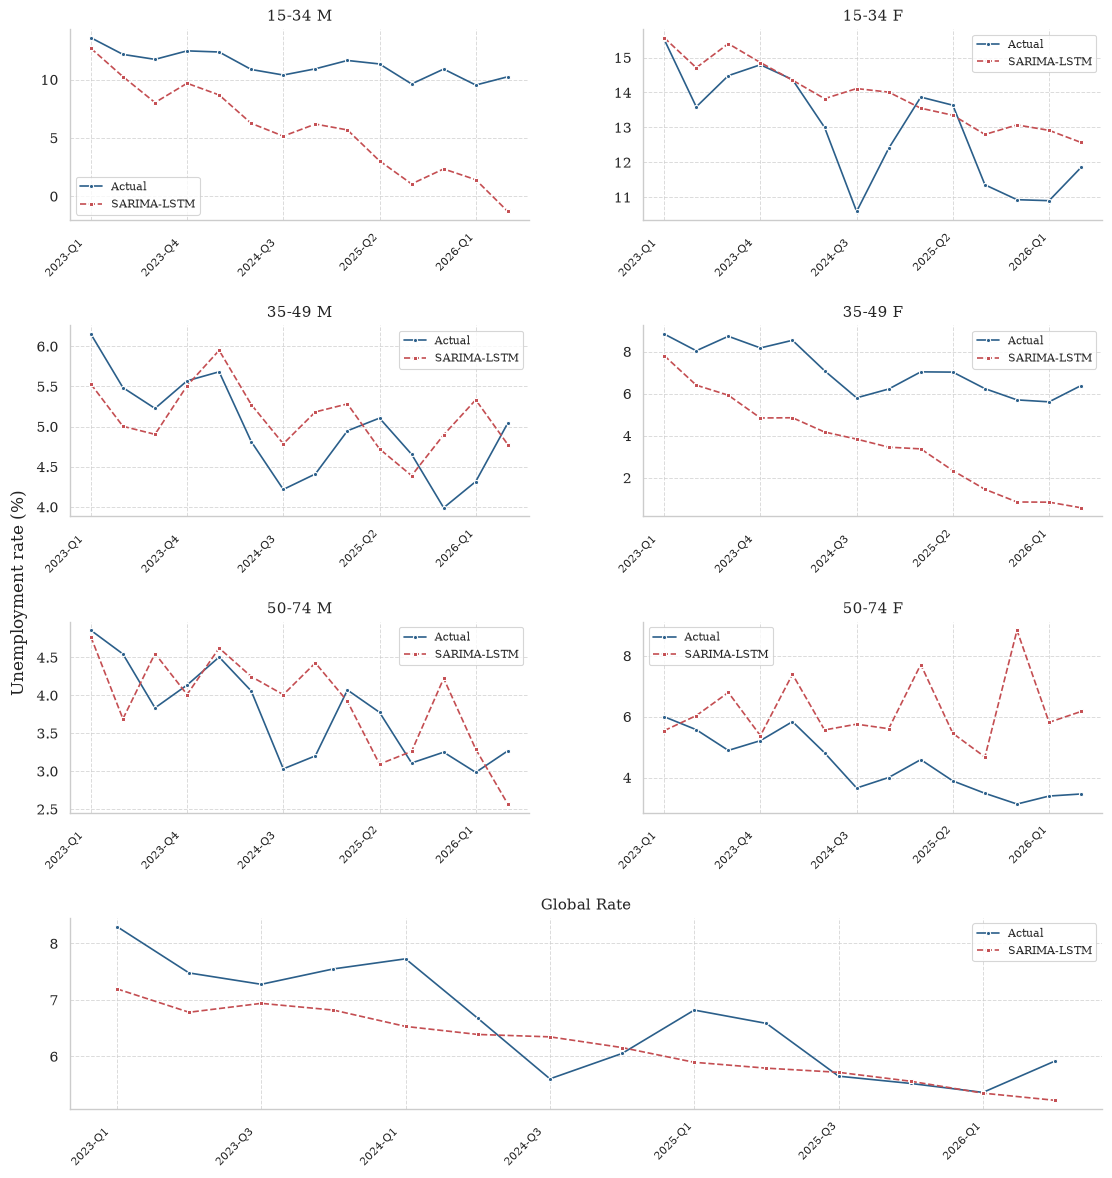

In [8]:


fig = plt.figure(figsize=(12,12))
gs = fig.add_gridspec(4,2,hspace=0.55,wspace=0.25)
axes = [fig.add_subplot(gs[i//2,i%2]) for i in range(6)]
axes.append(fig.add_subplot(gs[3,:]))

for i,(ax,col) in enumerate(zip(axes,series)):
    #leer de los archivos guardados en la carpeta SARIMA_LSTM_joint
    #df = hybrid_predictions[col]
    df = pd.read_csv(BASE /"results"/"SARIMA_LSTM_Joint" / f"pred_{col.replace(' ', '_')}.csv", index_col=0)
    x = df.index

    sns.lineplot(x=x,y=df["Observed"],ax=ax,color="#2B5F8A",
                 marker="o",markersize=3,linewidth=1.2,label="Actual")

    sns.lineplot(x=x,y=df["Hybrid"],ax=ax,color="#C44E52",
                 marker="s",markersize=3,linewidth=1.2,
                 linestyle="--",label="SARIMA-LSTM")

    ax.set_title(col.replace("_"," "),fontsize=11)
    ax.set(xlabel="",ylabel="")
    ticks = x[::2] if i==6 else x[::3]
    ax.set_xticks(ticks)
    ax.set_xticklabels(ticks,rotation=45,ha="right",fontsize=8)
    ax.grid(True,linestyle="--",linewidth=0.7,alpha=0.7)
    ax.legend(fontsize=8)
    sns.despine(ax=ax)

fig.supylabel("Unemployment rate (%)",fontsize=12,x=0.07)
fig.subplots_adjust(left=0.12,right=0.98,top=0.97,bottom=0.07)

IMG = BASE / "IMG"
IMG.mkdir(parents=True,exist_ok=True)
fig.savefig(IMG/"sarima_lstm_joint_forecast_test.pdf",bbox_inches="tight")
plt.show()

In [9]:
rng = np.random.default_rng(42)
B, block_size = 2000, 4
ci_results = []

for col in series:
    df = pd.read_csv(BASE/"results"/"SARIMA_LSTM_Joint"/f"pred_{col.replace(' ','_')}.csv")

    real = df["Observed"].to_numpy()
    pred = df["Hybrid"].to_numpy()
    n = len(real)

    if n < block_size:
        raise ValueError(f"{col}: test demasiado corto")

    def calc(y, p):
        e = y-p
        mask = y != 0
        return {
            "MSE": np.mean(e**2),
            "RMSE": np.sqrt(np.mean(e**2)),
            "MAE": np.mean(np.abs(e)),
            "MAPE": np.mean(np.abs(e[mask]/y[mask]))*100 if mask.any() else np.nan
        }

    point = calc(real, pred)
    boot = {m: [] for m in point}

    for _ in range(B):
        starts = rng.integers(0,n-block_size+1,size=int(np.ceil(n/block_size)))
        idx = np.concatenate([np.arange(s,s+block_size) for s in starts])[:n]

        for m,v in calc(real[idx],pred[idx]).items():
            boot[m].append(v)

    row = {"Serie": col}
    for m in point:
        lo,hi = np.nanpercentile(boot[m],[2.5,97.5])
        row[m] = round(point[m],4)
        row[f"{m} IC 95%"] = f"[{lo:.4f}, {hi:.4f}]"

    ci_results.append(row)

sarima_lstm_ci_df = pd.DataFrame(ci_results)
sarima_lstm_ci_df.to_csv(BASE/"results"/"SARIMA_LSTM_Joint"/"sarima_lstm_IC_test.csv",index=False)
display(sarima_lstm_ci_df)

,Serie,MSE,MSE IC 95%,RMSE,RMSE IC 95%,MAE,MAE IC 95%,MAPE,MAPE IC 95%
0,15-34 M,40.0654,"[13.1482, 62.6845]",6.3297,"[3.6260, 7.9174]",5.6153,"[3.3937, 7.6982]",52.2771,"[29.4280, 73.8610]"
1,15-34 F,2.0856,"[0.7600, 3.6575]",1.4442,"[0.8718, 1.9125]",1.0741,"[0.6360, 1.5345]",9.2286,"[4.9482, 13.6709]"
2,35-49 M,0.2994,"[0.1445, 0.4028]",0.5472,"[0.3801, 0.6346]",0.4810,"[0.3268, 0.5674]",10.2175,"[6.4037, 12.8897]"
3,35-49 F,13.8920,"[7.6937, 20.0735]",3.7272,"[2.7737, 4.4803]",3.4769,"[2.6430, 4.4033]",51.6879,"[34.4357, 69.6235]"
4,50-74 M,0.4156,"[0.2569, 0.6229]",0.6447,"[0.5068, 0.7893]",0.5185,"[0.3814, 0.6614]",14.8871,"[10.1871, 19.8764]"
5,50-74 F,5.2498,"[1.6480, 8.7985]",2.2912,"[1.2837, 2.9662]",1.8372,"[1.0594, 2.5224]",48.0323,"[21.8798, 71.2857]"
6,Global_Rate,0.4574,"[0.2485, 0.6189]",0.6763,"[0.4985, 0.7867]",0.5524,"[0.3424, 0.7099]",7.9441,"[5.3520, 10.0019]"
